In [13]:
import sys
print(sys.executable)

/Users/chan/miniconda3/envs/stat415_hw1_env/bin/python


In [14]:
!pip install numpy
!pip install pandas
!pip install matplotlib.pyplot
!pip install seaborn
import numpy as np               # Numerical operations
import pandas as pd             # DataFrames, CSVs, missing data handling
import matplotlib.pyplot as plt  # Basic plotting
import seaborn as sns            # Statistical plots, heatmaps

ERROR: Could not find a version that satisfies the requirement matplotlib.pyplot (from versions: none)
ERROR: No matching distribution found for matplotlib.pyplot


1. Perform preliminary data quality checks, such as identifying duplicated columns and columns with entirely missing data. Determine how to manage these issues and justify your approach for handling them.


In [15]:
# Load your data
file_path = 'data/CreditCardFraud_updated.csv'
clean_data = pd.read_csv(file_path)

# Check for duplicated columns
duplicated_columns = clean_data.columns[clean_data.columns.duplicated()]
if not duplicated_columns.empty:
    print("Duplicated columns found:", duplicated_columns)
    # Drop duplicated columns
    clean_data = clean_data.loc[:, ~clean_data.columns.duplicated()]

# Check for columns with identical data
duplicate_cols = []
print_cols = []
cols = clean_data.columns

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        if clean_data[cols[i]].equals(clean_data[cols[j]]):
            duplicate_cols.append(cols[j])
            print_cols.append((cols[i], cols[j]))

clean_data = clean_data.drop(columns = duplicate_cols)
print("Columns with identical data:", print_cols)


# Check for columns with entirely missing data
missing_data_columns = clean_data.columns[clean_data.isnull().all()]
if not missing_data_columns.empty:
    print("Columns with entirely missing data:", missing_data_columns)
    # Drop columns with entirely missing data
    clean_data = clean_data.drop(columns=missing_data_columns)

clean_data = clean_data.drop(columns="Unnamed: 0")


Columns with identical data: [('accountNumber', 'customerId'), ('echoBuffer', 'merchantCity'), ('echoBuffer', 'merchantState'), ('echoBuffer', 'merchantZip'), ('echoBuffer', 'posOnPremises'), ('echoBuffer', 'recurringAuthInd'), ('merchantCity', 'merchantState'), ('merchantCity', 'merchantZip'), ('merchantCity', 'posOnPremises'), ('merchantCity', 'recurringAuthInd'), ('merchantState', 'merchantZip'), ('merchantState', 'posOnPremises'), ('merchantState', 'recurringAuthInd'), ('merchantZip', 'posOnPremises'), ('merchantZip', 'recurringAuthInd'), ('posOnPremises', 'recurringAuthInd')]
Columns with entirely missing data: Index(['echoBuffer'], dtype='object')


Question 2 Code: 

In [16]:
print("old length", len(clean_data))# Apply the function to clean_data

# Function to remove all outliers for all numerical variables exept those exclude.
# Use the Tuker Method for Identifying Outliers
def remove_outliers(data, LB_factor, UB_factor, exclude):
    numerical_cols = data.select_dtypes(include=[np.number]).columns
    for column in numerical_cols:
        if column not in exclude:
            Q1 = data[column].quantile(0.25)
            Q3 = data[column].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - LB_factor * IQR
            upper_bound = Q3 + UB_factor * IQR
            data = data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]
    return data

clean_data = remove_outliers(clean_data, 1.5, 1.5, ['posConditionCode'])

def remove_certain_outliers_2(data, lower_bound, upper_bound, numerical_cols):
    for column in numerical_cols:
        # identify and print the outliers
        outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
        #print(f"Outliers detected in {column}: {len(outliers)}")
        # remove them
        data = data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]

         # # Plot histogram with dynamic labels
            # plt.figure(figsize=(10, 6))
            # plt.hist(data[column], bins=30, alpha=0.7, color='blue', edgecolor='black')
            # plt.title(f'Histogram of {column}')
            # plt.xlabel(column)
            # plt.ylabel('Frequency')
            # plt.grid(axis='y', alpha=0.75)
            # plt.show()

    return data

clean_data = remove_certain_outliers_2(clean_data, 0, 40, ['posConditionCode'])

old length 786363


Question 3 Code:

In [17]:
missing_counts = clean_data.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)
missing_cols = missing_counts.index

print("Columns with missing values:\n")
print(missing_counts)

# Create missing-value indicator columns (optional, can keep if needed)
for col in missing_cols:
    clean_data[col + '_missing'] = clean_data[col].isnull().astype(int)

# Replace missing values in selected categorical columns with a new category
for column in ['acqCountry', 'merchantCountryCode', 'transactionType', 'posEntryMode', 'posConditionCode']:
    clean_data[column] = clean_data[column].fillna('Missing')
    print(f"Added 'Missing' category for null values in {column}")

Columns with missing values:

acqCountry             3371
merchantCountryCode     539
transactionType         516
dtype: int64
Added 'Missing' category for null values in acqCountry
Added 'Missing' category for null values in merchantCountryCode
Added 'Missing' category for null values in transactionType
Added 'Missing' category for null values in posEntryMode
Added 'Missing' category for null values in posConditionCode


Question 4 Code:

In [18]:
# Identify potential time-related columns based on common naming conventions
time_columns = [col for col in clean_data.columns if 'date' in col.lower() or 'time' in col.lower()]
print("Potential time-related columns:", time_columns)

# Convert time-related columns to datetime format
for col in time_columns:
    clean_data[col] = pd.to_datetime(clean_data[col], errors='coerce')
    print(f"Converted {col} to datetime format.")

# Extract meaningful features from time variables
for col in time_columns:
    clean_data[f'{col}_year'] = clean_data[col].dt.year
    clean_data[f'{col}_month'] = clean_data[col].dt.month
    clean_data[f'{col}_day'] = clean_data[col].dt.day
    clean_data[f'{col}_hour'] = clean_data[col].dt.hour
    clean_data[f'{col}_weekday'] = clean_data[col].dt.weekday
    print(f"Extracted features from {col}.")

# Display the first few rows to verify the changes
print(clean_data.head())

# Identify and drop columns that contain only NA values
na_only_columns = clean_data.columns[clean_data.isnull().all()]
clean_data.drop(columns=na_only_columns, inplace=True)

# Print the names of the columns that were removed
print("Removed columns with only NA values:", na_only_columns.tolist())

# Display the head of only the newly created time-related feature columns
new_time_features = [col for col in clean_data.columns if any(suffix in col for suffix in ['_year', '_month', '_day', '_hour', '_weekday'])]
print(clean_data[new_time_features].head())

Potential time-related columns: ['transactionDateTime', 'currentExpDate', 'accountOpenDate', 'dateOfLastAddressChange', 'expirationDateKeyInMatch']
Converted transactionDateTime to datetime format.
Converted currentExpDate to datetime format.
Converted accountOpenDate to datetime format.
Converted dateOfLastAddressChange to datetime format.
Converted expirationDateKeyInMatch to datetime format.


/var/folders/nz/dzmdyljd0f7cgh05j0bjzv7h0000gn/T/ipykernel_89049/2950088658.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  clean_data[col] = pd.to_datetime(clean_data[col], errors='coerce')


Extracted features from transactionDateTime.
Extracted features from currentExpDate.
Extracted features from accountOpenDate.
Extracted features from dateOfLastAddressChange.
Extracted features from expirationDateKeyInMatch.
   accountNumber  creditLimit  availableMoney transactionDateTime  \
0      737265056       5000.0          5000.0 2016-08-13 14:27:32   
1      737265056       5000.0          5000.0 2016-10-11 05:05:54   
2      737265056       5000.0          5000.0 2016-11-08 09:18:39   
3      737265056       5000.0          5000.0 2016-12-10 02:14:50   
4      830329091       5000.0          5000.0 2016-03-24 21:04:46   

   transactionAmount         merchantName acqCountry merchantCountryCode  \
0              98.55                 Uber         US                  US   
1              74.51          AMC #191138         US                  US   
2               7.47           Play Store         US                  US   
3               7.47           Play Store         US    

Question 5 Code:

In [19]:
# Create a flag for valid CVV length
clean_data['is_valid_cardCVV'] = clean_data['cardCVV'].astype(str).str.len() == 3
clean_data['is_valid_enteredCVV'] = clean_data['enteredCVV'].astype(str).str.len() == 3

# Create a flag for valid card last 4 digits length
clean_data['is_valid_cardLast4Digits'] = clean_data['cardLast4Digits'].astype(str).str.len() == 4

# Print the first few rows of the new flags to verify
#print(clean_data[['is_valid_cardCVV', 'is_valid_enteredCVV', 'is_valid_cardLast4Digits']].head())
print(len(clean_data[clean_data['is_valid_cardCVV'] == False]['cardCVV'])) # all card CVV values are good
print(len(clean_data[clean_data['is_valid_enteredCVV'] == False]['enteredCVV'])) # all card CVV values are good
print(clean_data[clean_data['is_valid_enteredCVV'] == False]['enteredCVV']) # all card CVV values are good

# change all these numbers into strings
clean_data['cardCVV_str'] = [str(cvv) for cvv in clean_data['cardCVV']]
clean_data['enteredCVV_str'] = [str(cvv).zfill(3) if cvv < 100 else str(cvv) for cvv in clean_data['enteredCVV']]
clean_data['cardLast4Digits_str'] = [str(cvv).zfill(4) if cvv < 1000 else str(cvv) for cvv in clean_data['cardLast4Digits']]

# Check that 'enteredCVV_str' has exactly 3 characters
invalid_enteredCVV_str = clean_data[clean_data['enteredCVV_str'].str.len() != 3]
print(f"Number of invalid 'enteredCVV_str' entries: {len(invalid_enteredCVV_str)}")

# Check that 'cardLast4Digits_str' has exactly 4 characters
invalid_cardLast4Digits_str = clean_data[clean_data['cardLast4Digits_str'].str.len() != 4]
print(f"Number of invalid 'cardLast4Digits_str' entries: {len(invalid_cardLast4Digits_str)}")

print()

0
161
4798      51
7154      67
12885     21
30914      9
41517     36
          ..
749716    34
759533     6
770275    37
775447    61
777015    96
Name: enteredCVV, Length: 161, dtype: int64
Number of invalid 'enteredCVV_str' entries: 0
Number of invalid 'cardLast4Digits_str' entries: 0



Question 6 Code:

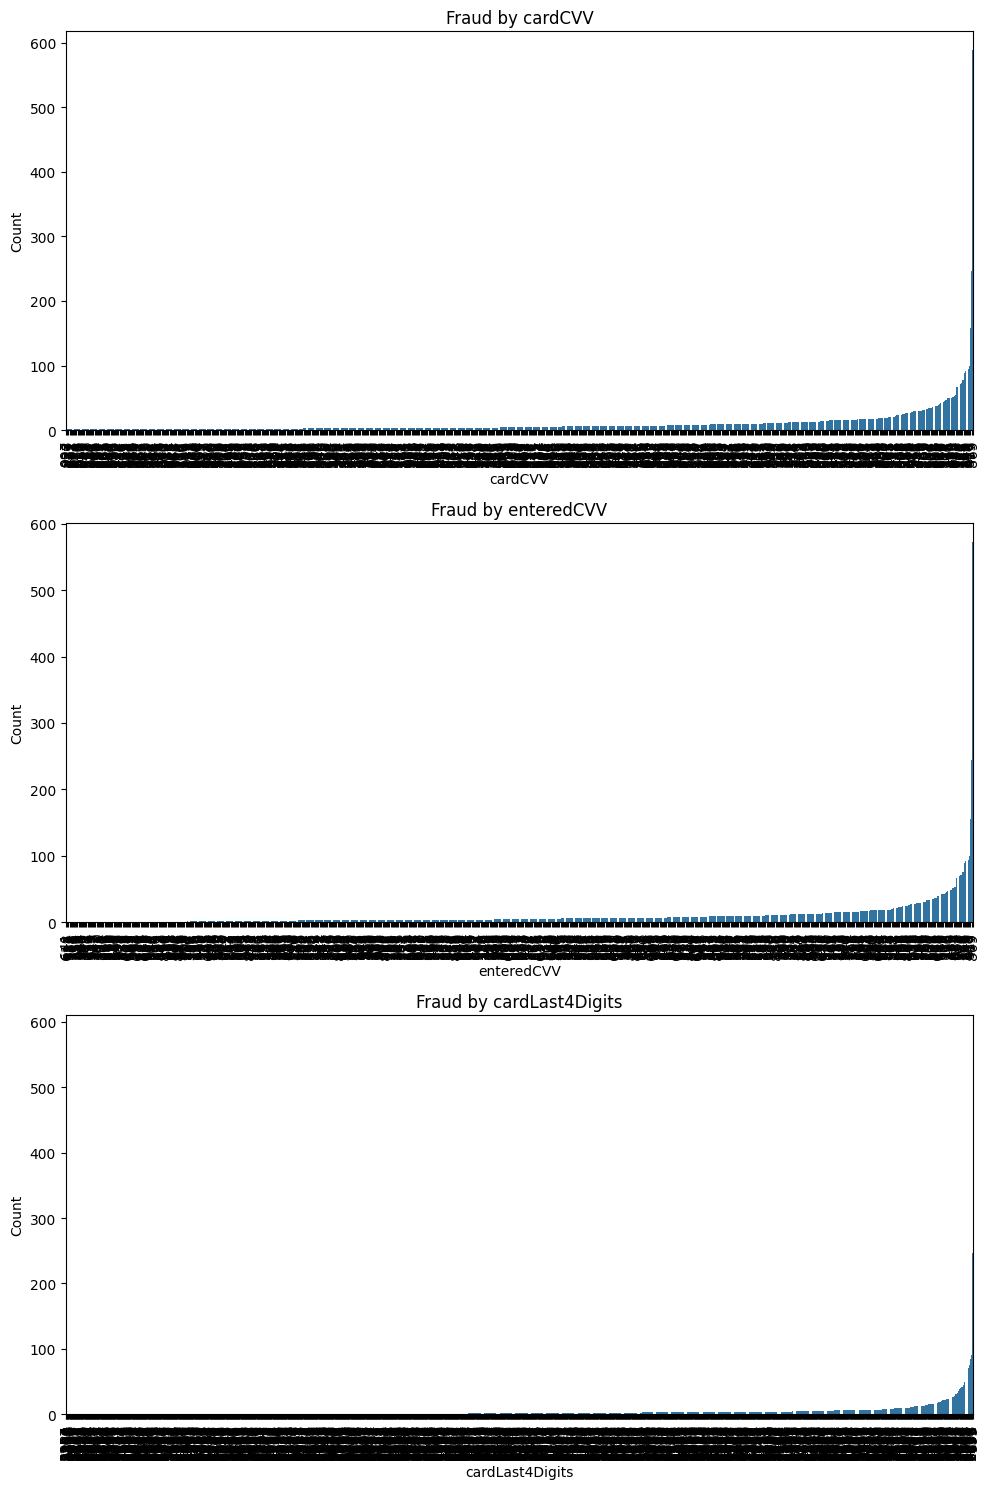

In [20]:
# Prepare the data for visualization, filtering only fraud cases
fraud_analysis = clean_data[clean_data['isFraud'] == True][['cardCVV', 'enteredCVV', 'cardLast4Digits']]

# Create a bar chart for each variable
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

# Plot for cardCVV
sns.countplot(data=fraud_analysis, x='cardCVV', ax=axes[0],
                  order=fraud_analysis['cardCVV'].value_counts().sort_values().index)
axes[0].set_title('Fraud by cardCVV')
axes[0].set_xlabel('cardCVV')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=90)

# Plot for enteredCVV
sns.countplot(data=fraud_analysis, x='enteredCVV', ax=axes[1],
                  order=fraud_analysis['enteredCVV'].value_counts().sort_values().index)
axes[1].set_title('Fraud by enteredCVV')
axes[1].set_xlabel('enteredCVV')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=90)

# Plot for cardLast4Digits
sns.countplot(data=fraud_analysis, x='cardLast4Digits', ax=axes[2],
                  order=fraud_analysis['cardLast4Digits'].value_counts().sort_values().index)
axes[2].set_title('Fraud by cardLast4Digits')
axes[2].set_xlabel('cardLast4Digits')
axes[2].set_ylabel('Count')
axes[2].tick_params(axis='x', rotation=90)

plt.tight_layout(); plt.show()

Question 7 Code: 

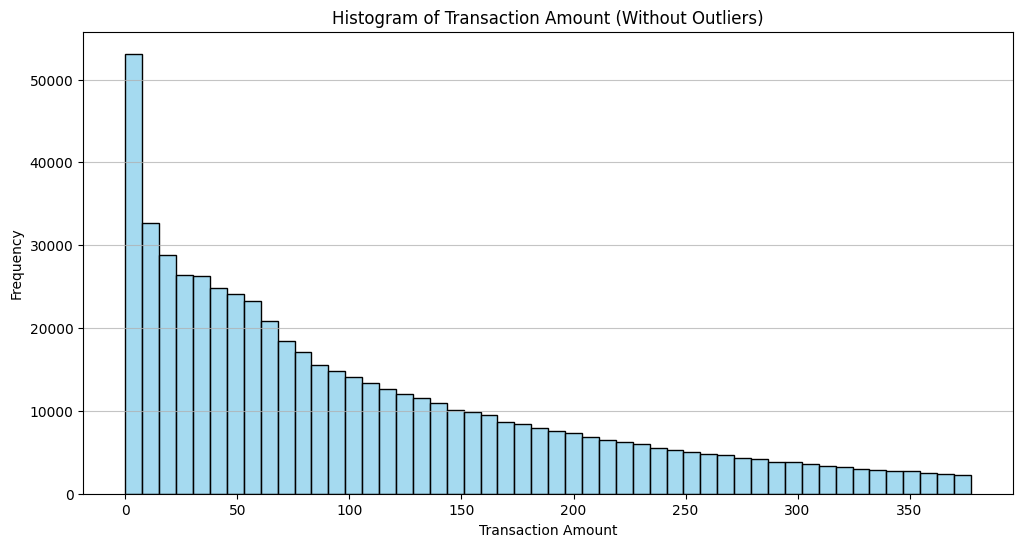

/var/folders/nz/dzmdyljd0f7cgh05j0bjzv7h0000gn/T/ipykernel_89049/1069571015.py:25: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(filtered_data['transactionAmount'], shade=True, color='salmon')


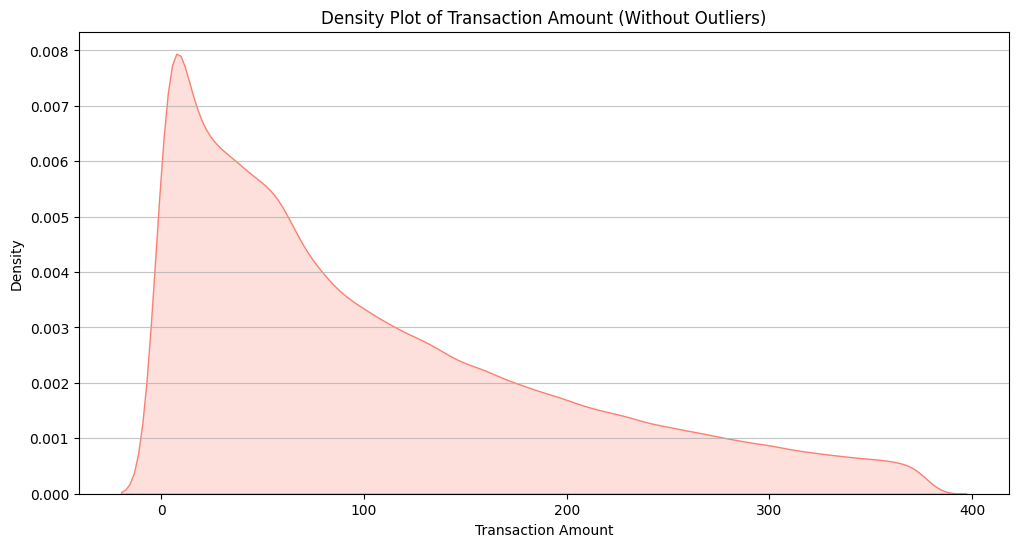

In [21]:
# Calculate the IQR for transactionAmount
Q1 = clean_data['transactionAmount'].quantile(0.25)
Q3 = clean_data['transactionAmount'].quantile(0.75)
IQR = Q3 - Q1

# Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the data to exclude outliers
filtered_data = clean_data[(clean_data['transactionAmount'] >= lower_bound) & 
                               (clean_data['transactionAmount'] <= upper_bound)]

# Plot a histogram for transactionAmount without outliers
plt.figure(figsize=(12, 6))
sns.histplot(filtered_data['transactionAmount'], bins=50, kde=False, color='skyblue')
plt.title('Histogram of Transaction Amount (Without Outliers)')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

# Plot a density plot for transactionAmount without outliers
plt.figure(figsize=(12, 6))
sns.kdeplot(filtered_data['transactionAmount'], shade=True, color='salmon')
plt.title('Density Plot of Transaction Amount (Without Outliers)')
plt.xlabel('Transaction Amount')
plt.ylabel('Density')
plt.grid(axis='y', alpha=0.75)
plt.show()

Question 8 Code:

/var/folders/nz/dzmdyljd0f7cgh05j0bjzv7h0000gn/T/ipykernel_89049/3295650023.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=fraud_rate.index, y=fraud_rate.values, ax=axes[i], palette='viridis')
/var/folders/nz/dzmdyljd0f7cgh05j0bjzv7h0000gn/T/ipykernel_89049/3295650023.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=fraud_rate.index, y=fraud_rate.values, ax=axes[i], palette='viridis')
/var/folders/nz/dzmdyljd0f7cgh05j0bjzv7h0000gn/T/ipykernel_89049/3295650023.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=fraud_rate.ind

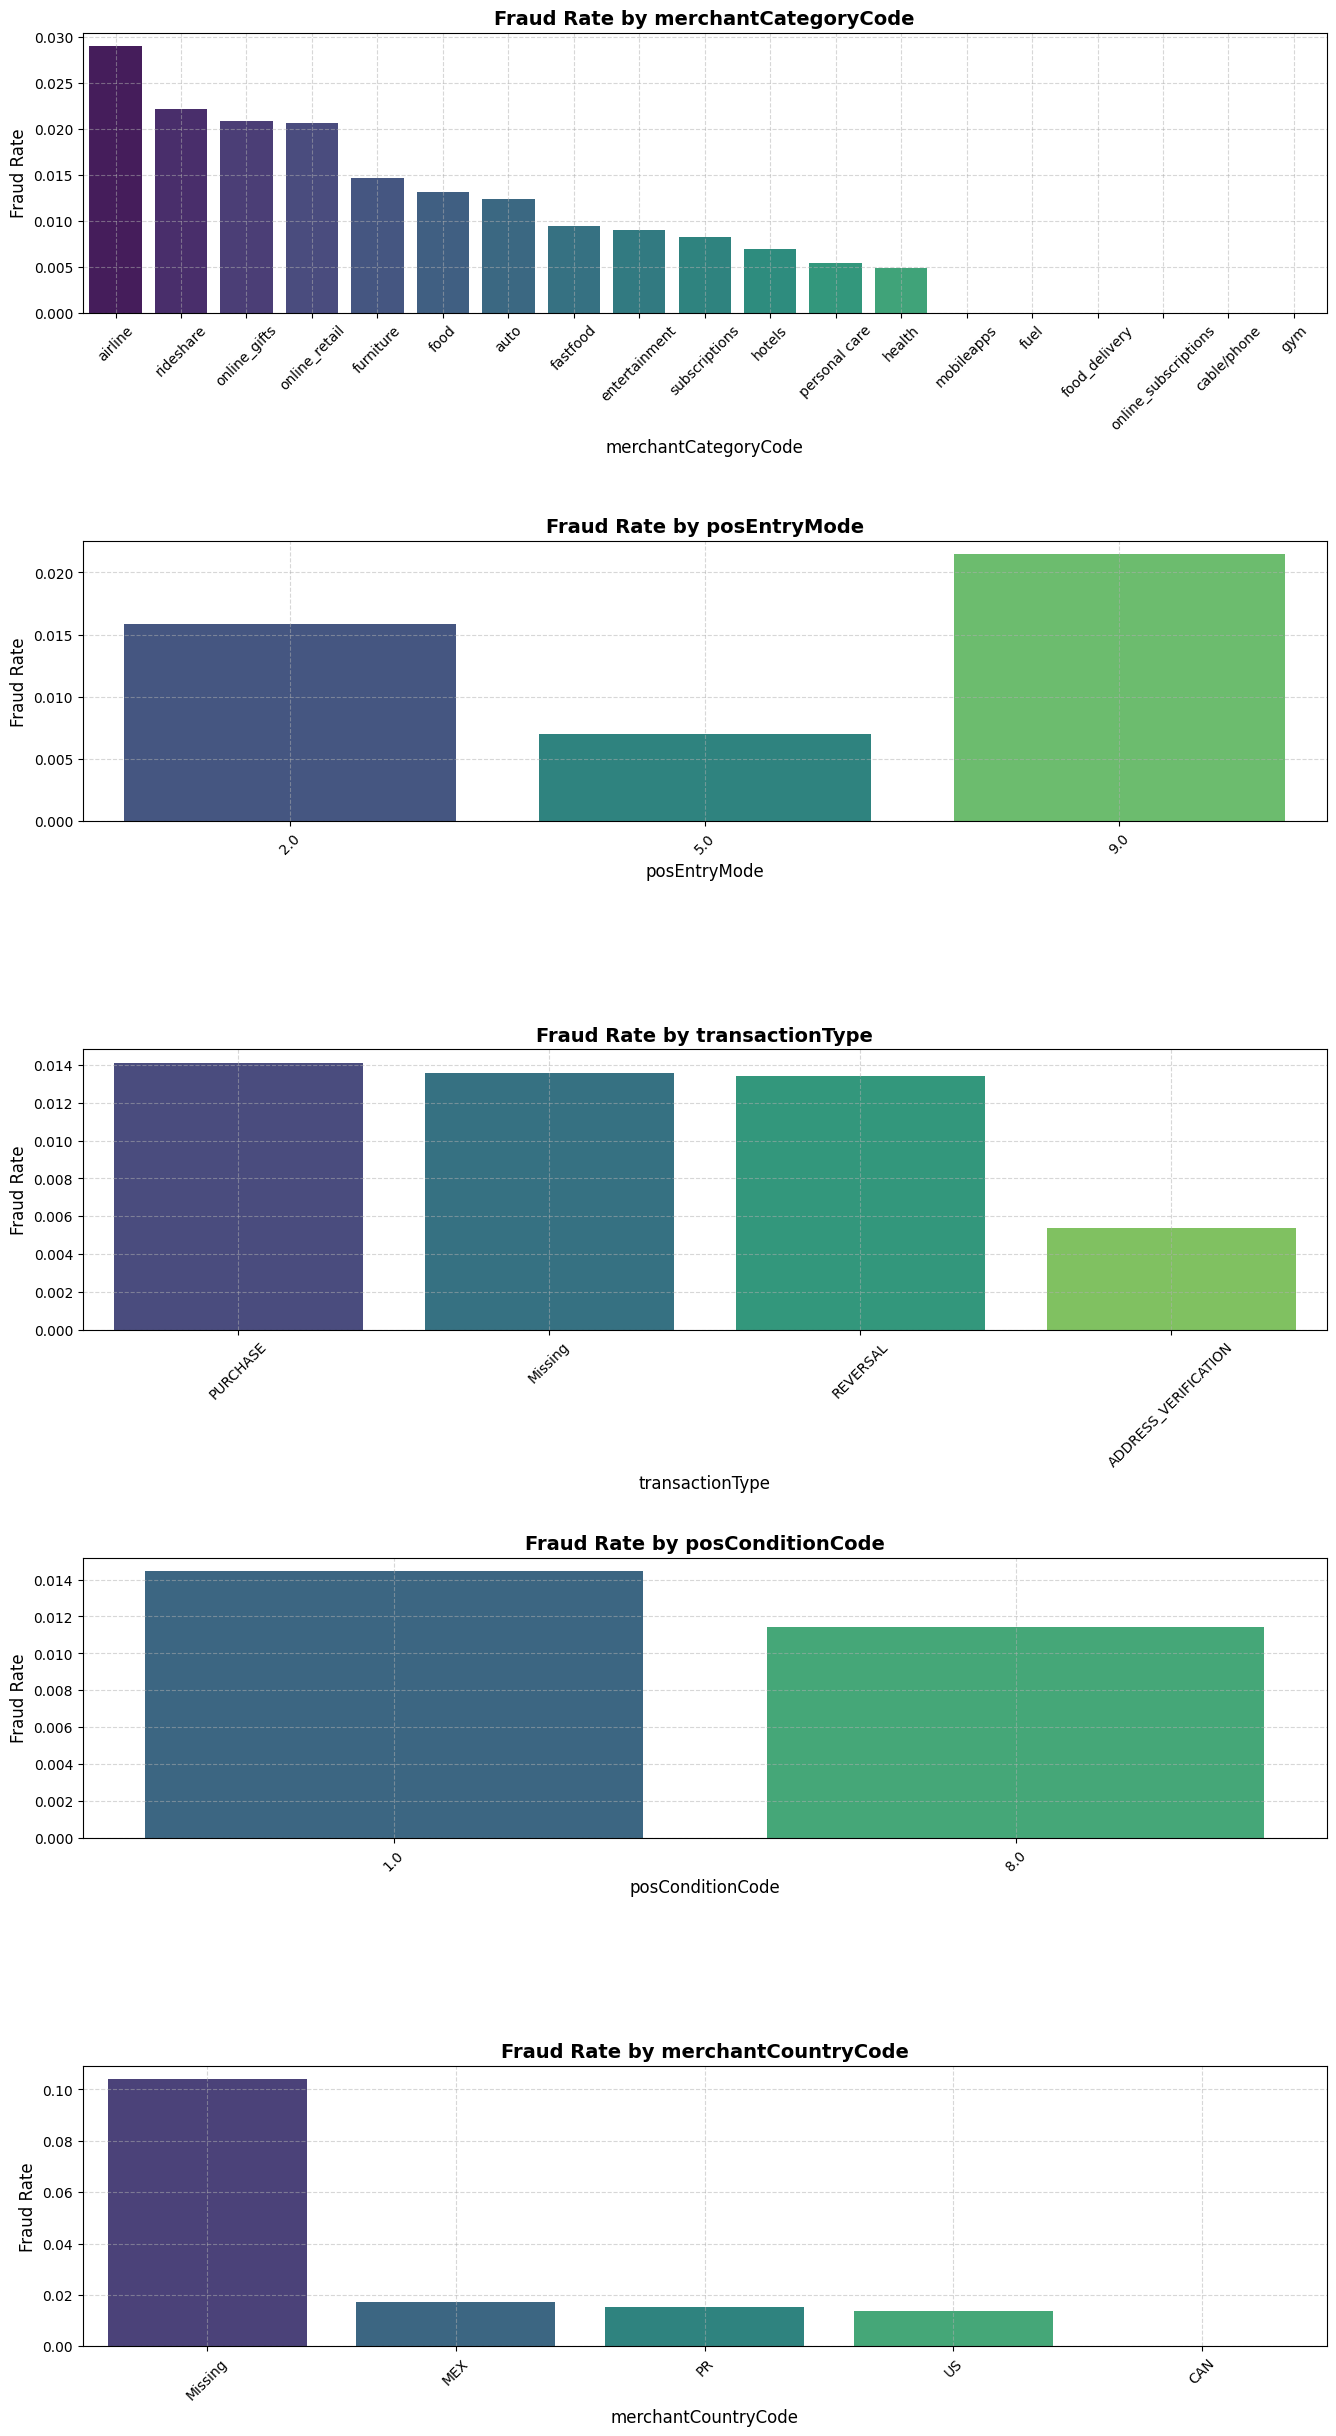

[1. 8.]


In [ ]:
def plot_fraud_rate_by_category():
    # List of categorical columns to analyze
    categorical_columns = [
        'merchantCategoryCode',
        'posEntryMode',
        'transactionType',
        'posConditionCode',
        'merchantCountryCode'
    ]

    # Set up the figure for subplots
    fig, axes = plt.subplots(len(categorical_columns), 1, figsize=(14, 5 * len(categorical_columns)))

    for i, column in enumerate(categorical_columns):
        # Calculate fraud rate for each category
        fraud_rate = clean_data.groupby(column)['isFraud'].mean().sort_values(ascending=False)

        # Plot the fraud rate
        sns.barplot(x=fraud_rate.index, y=fraud_rate.values, ax=axes[i], palette='viridis')
        axes[i].set_title(f'Fraud Rate by {column}', fontsize=14, weight='bold')
        axes[i].set_xlabel(column, fontsize=12)
        axes[i].set_ylabel('Fraud Rate', fontsize=12)
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout(pad=3.0)
    plt.show()

plot_fraud_rate_by_category()

Question 9 Code:

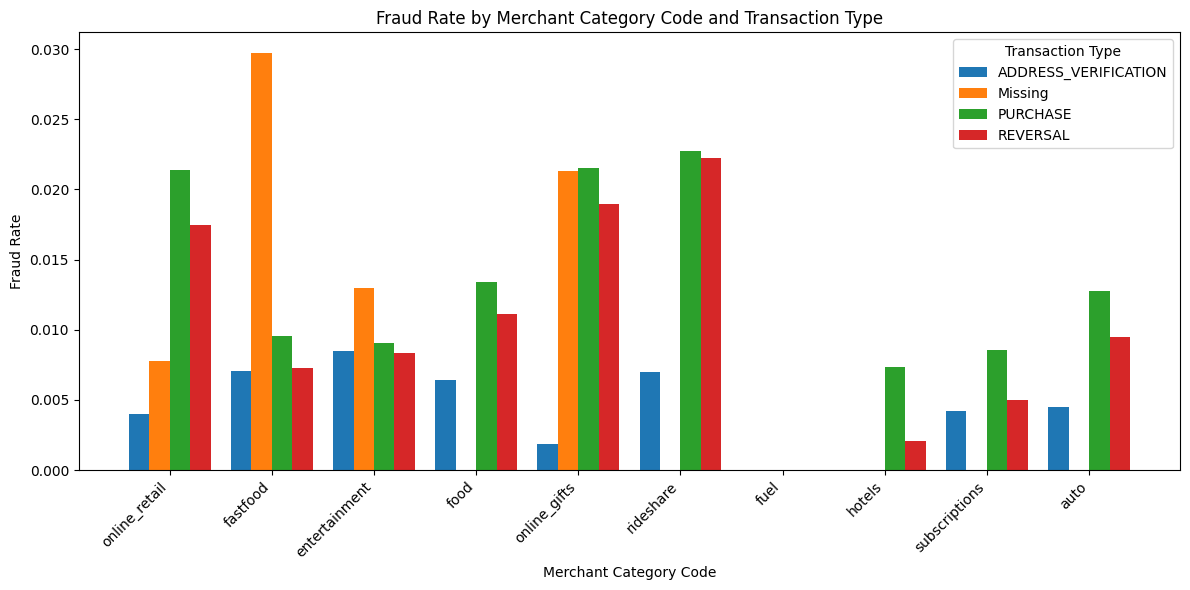

In [26]:
# 1. Compute fraud rates
grp = (
    clean_data
    .groupby(['merchantCategoryCode', 'transactionType'])['isFraud']
    .mean()
    .reset_index()
)
pivot = grp.pivot(
    index='merchantCategoryCode',
    columns='transactionType',
    values='isFraud'
).fillna(0)

# 2. (Optional) Limit to the top 10 merchant categories by frequency
top_cats = clean_data['merchantCategoryCode'].value_counts().nlargest(10).index
pivot = pivot.loc[top_cats]

# 3. Plot a grouped bar chart
fig, ax = plt.subplots(figsize=(12, 6))
types = pivot.columns.tolist()
x = np.arange(len(pivot.index))
width = 0.8 / len(types)

for i, t in enumerate(types):
    ax.bar(x + i*width, pivot[t], width, label=t)

# 4. Tidy up axes and labels
ax.set_xticks(x + width*(len(types)-1)/2)
ax.set_xticklabels(pivot.index, rotation=45, ha='right')
ax.set_xlabel('Merchant Category Code')
ax.set_ylabel('Fraud Rate')
ax.set_title('Fraud Rate by Merchant Category Code and Transaction Type')
ax.legend(title='Transaction Type')
plt.tight_layout()
plt.show()

Question 10 Code:

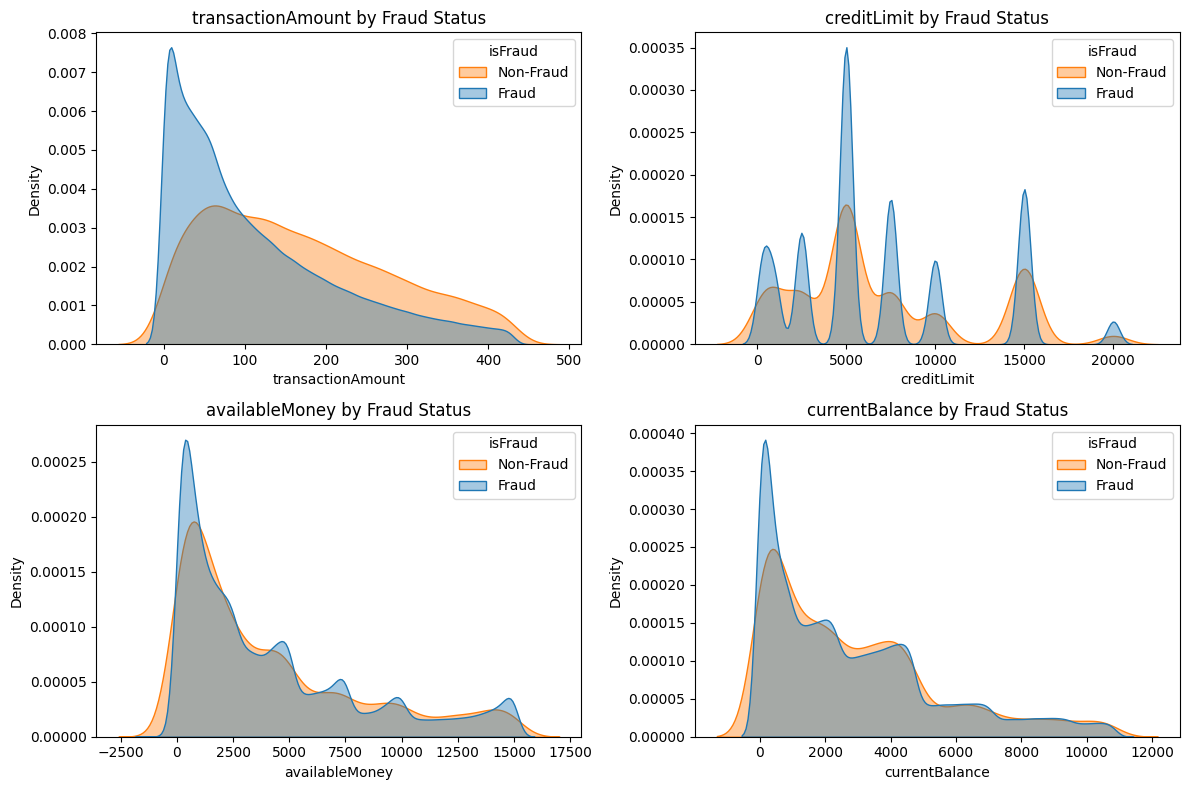

In [32]:
# # 1. Identify all numeric columns except the target
# numeric_cols = [
#     col for col in clean_data.columns 
#     if col != 'isFraud' and pd.api.types.is_numeric_dtype(clean_data[col])
# ]

# all the cont variables
numeric_cols= ['transactionAmount', 'creditLimit', 'availableMoney', 'currentBalance']

# 2. Set up the grid: one subplot per numeric variable
n = len(numeric_cols)
cols = 2
rows = (n + 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(12, 4*rows))
axes = axes.flatten()

# 3. Plot KDEs for each variable
for ax, col in zip(axes, numeric_cols):
    sns.kdeplot(data=clean_data, x=col, hue='isFraud',
                common_norm=False, fill=True, alpha=0.4, ax=ax)
    ax.set_title(f'{col} by Fraud Status')
    ax.legend(title='isFraud', labels=['Non‑Fraud','Fraud'])
    ax.set_xlabel(col)
    ax.set_ylabel('Density')

# 4. Remove any extra axes if n is odd
for extra in axes[len(numeric_cols):]:
    fig.delaxes(extra)

plt.tight_layout()
plt.show()

Question 11 Code:

In [34]:
# ——— 1. Conditions ———
#   • Same card (last‑4 digits)
#   • Same transaction amount
#   • Swipe occurs within X seconds of the prior swipe
card_col       = 'cardLast4Digits'
amount_col     = 'transactionAmount'
time_col       = 'transactionDateTime'      # your timestamp column
threshold_secs = 60                     # e.g. swipes within 1 minute

# ——— 2. Prepare and sort ———
df = clean_data.copy()
df[time_col] = pd.to_datetime(df[time_col])
df = df.sort_values([card_col, amount_col, time_col])

# ——— 3. Compute inter‑swipe intervals ———
df['delta_sec'] = (
    df
    .groupby([card_col, amount_col])[time_col]
    .diff()
    .dt.total_seconds()
)

# ——— 4. Flag multi‑swipes ———
#    The first swipe in each (card, amount) group has delta_sec = NaN → we leave it False
df['is_multi_swipe'] = df['delta_sec'].le(threshold_secs)

# ——— 5. Calculate percentages ———
total_tx       = len(df)
multi_swipe_tx = df['is_multi_swipe'].sum()
pct_tx         = multi_swipe_tx / total_tx * 100

total_amt        = df[amount_col].sum()
multi_swipe_amt  = df.loc[df['is_multi_swipe'], amount_col].sum()
pct_amt          = multi_swipe_amt / total_amt * 100

# ——— 6. Report ———
print(f"Conditions: same {card_col}, same {amount_col}, within {threshold_secs}s")
print(f"Total transactions:                {total_tx}")
print(f"Multi‑swipe transactions (extra):  {multi_swipe_tx}  ({pct_tx:.2f}%)")
print(f"Total dollar volume:               ${total_amt:,.2f}")
print(f"Volume from multi‑swipes (extra):  ${multi_swipe_amt:,.2f}  ({pct_amt:.2f}%)")

Conditions: same cardLast4Digits, same transactionAmount, within 60s
Total transactions:                579743
Multi‑swipe transactions (extra):  3277  (0.57%)
Total dollar volume:               $65,483,358.79
Volume from multi‑swipes (extra):  $394,114.62  (0.60%)


Question 12 Code:

In [35]:
# Compute class counts and percentages
counts = clean_data['isFraud'].value_counts()
percent = clean_data['isFraud'].value_counts(normalize=True) * 100
imbalance = pd.DataFrame({
    'count': counts,
    'percentage': percent
})
print(imbalance)


          count  percentage
isFraud                    
False    571700   98.612661
True       8043    1.387339


Question 13 Code:

In [38]:
!pip install imblearn
from imblearn.over_sampling import RandomOverSampler

X = clean_data.drop('isFraud', axis=1)
y = clean_data['isFraud']
ros = RandomOverSampler(sampling_strategy='auto', random_state=42)
X_res, y_res = ros.fit_resample(X, y)

print(y.value_counts())
# False    571700
# True       8043

print(y_res.value_counts())
# False    571700
# True     571700


isFraud
False    571700
True       8043
Name: count, dtype: int64
isFraud
False    571700
True     571700
Name: count, dtype: int64
